# AI-Based Fruit and Vegetable Classification

## 1. Introduction

This project aims to develop a machine learning system capable of
identifying fruits and vegetables from images.

The classification model will be combined with nutritional information
from the Swedish Food Agency (Livsmedelsverket).

### Business Question

Can we develop a machine learning model that automatically identifies
fruits and vegetables from images and combines the results with reliable
nutritional information?

### Project Objectives

- Explore and understand the image dataset.
- Preprocess and prepare images for machine learning.
- Develop a baseline classification model.
- Train a Convolutional Neural Network (CNN).
- Evaluate model performance using accuracy, macro-F1 and a confusion matrix.
- Compare different classification approaches.
- Support the integration of nutritional information into an application.

In [2]:
from pathlib import Path

# Show the current working directory
print("Current working directory:")
print(Path.cwd())

# Show files and folders in the current directory
print("\nFiles and folders:")
for item in Path.cwd().iterdir():
    print(item.name)

Current working directory:
c:\Users\JRD\GroupProjectGrupp1BI25\group-project\notebooks

Files and folders:
Dargys.ipynb
Fridas.ipynb
Jessikas.ipynb
test.md


Finding dataset

Path.cwd()  = Shows where in the folder Python is working
.parent     = directs one folder up
/ "data"    = pints to the folder "data"
.exists()   = checks if the file exists

In [4]:
from pathlib import Path

# Go one folder up to the project root
project_root = Path.cwd().parent

# Define the data folder
data_path = project_root / "data"

print("Project root:", project_root)
print("Data folder:", data_path)

# Check if the data folder exists
print("Data folder exists:", data_path.exists())

Project root: c:\Users\JRD\GroupProjectGrupp1BI25\group-project
Data folder: c:\Users\JRD\GroupProjectGrupp1BI25\group-project\data
Data folder exists: True


In [5]:
# Check the contents of the data folder

if data_path.exists():

    print("Contents of the data folder:\n")

    for item in sorted(data_path.iterdir()):
        if item.is_dir():
            print(f"📁 Folder: {item.name}")
        else:
            print(f"📄 File: {item.name}")

else:
    print("Data folder not found!")

Contents of the data folder:

📄 File: data.txt
📁 Folder: raw_images


In [6]:
# Define the folder containing the raw images
raw_images_path = data_path / "raw_images"

print("Raw images folder:", raw_images_path)
print("\nContents of raw_images:\n")

if raw_images_path.exists():
    for item in sorted(raw_images_path.iterdir()):
        if item.is_dir():
            print(f"📁 {item.name}")
        else:
            print(f"📄 {item.name}")
else:
    print("Raw images folder not found!")

Raw images folder: c:\Users\JRD\GroupProjectGrupp1BI25\group-project\data\raw_images

Contents of raw_images:

📁 agata_potato
📁 asterix_potato
📁 cashew
📁 diamond_peach
📁 fuji_apple
📁 granny_smith_apple
📁 honneydew_melon
📁 kiwi
📁 nectarine
📁 onion
📁 orange
📁 plum
📁 spanish_pear
📁 taiti_lime
📁 watermelon


In [7]:
# Supported image file formats
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# Find all image files, including images in subfolders
image_files = [
    file
    for file in raw_images_path.rglob("*")
    if file.is_file() and file.suffix.lower() in image_extensions
]

print("Total number of images:", len(image_files))

# Show a few example file paths
print("\nExample image files:")

for file in image_files[:5]:
    print(file.relative_to(raw_images_path))

Total number of images: 2633

Example image files:
agata_potato\agata_potato_001.jpg
agata_potato\agata_potato_002.jpg
agata_potato\agata_potato_003.jpg
agata_potato\agata_potato_004.jpg
agata_potato\agata_potato_005.jpg


## 2. Exploratory Data Analysis (EDA)

### 2.1 Dataset Selection and Class Mapping

The original dataset contains 15 fruit and vegetable classes.

To align the dataset with the project objectives, four classes
are excluded from the analysis:

- Cashew
- Diamond peach
- Orange
- Tahiti lime

Additionally, different varieties of apples and potatoes are
combined into broader categories.

- Fuji apple and Granny Smith apple are mapped to "apple".
- Agata potato and Asterix potato are mapped to "potato".

This results in 9 target classes.

The original image files are preserved. Filtering and class
mapping are performed in Python without modifying the raw dataset.

In [8]:
# Classes excluded from the analysis
excluded_classes = {
    "cashew",
    "diamond_peach",
    "orange",
    "taiti_lime"
}

# Mapping of original classes to broader categories
class_mapping = {
    "fuji_apple": "apple",
    "granny_smith_apple": "apple",
    "agata_potato": "potato",
    "asterix_potato": "potato"
}

# Create a list of image paths and their target labels
dataset = []

for image_path in image_files:

    original_class = image_path.parent.name

    # Skip excluded classes
    if original_class in excluded_classes:
        continue

    # Map apple and potato varieties to broader categories
    target_class = class_mapping.get(
        original_class,
        original_class
    )

    dataset.append({
        "image_path": image_path,
        "original_class": original_class,
        "target_class": target_class
    })

# Display dataset information
print("Original number of images:", len(image_files))
print("Filtered number of images:", len(dataset))

# Display the remaining target classes
target_classes = sorted({
    item["target_class"] for item in dataset
})

print("\nNumber of target classes:", len(target_classes))
print("\nTarget classes:")

for class_name in target_classes:
    print("-", class_name)

Original number of images: 2633
Filtered number of images: 2003

Number of target classes: 9

Target classes:
- apple
- honneydew_melon
- kiwi
- nectarine
- onion
- plum
- potato
- spanish_pear
- watermelon


In [11]:
import pandas as pd

# Convert the filtered dataset into a DataFrame
df = pd.DataFrame(dataset)

# Count images per target class
class_counts = df["target_class"].value_counts().sort_index()

# Calculate percentage distribution
class_percentages = (class_counts / len(df) * 100).round(1)

# Create a summary table
class_distribution = pd.DataFrame({
    "Number of Images": class_counts,
    "Percentage (%)": class_percentages
})

# Add a total row
class_distribution.loc["Total"] = [
    class_counts.sum(),
    100.0
]

# Display the results
print("Class Distribution:\n")
display(class_distribution)

print("\nTotal images:", len(df))
print("Total classes:", df["target_class"].nunique())

Class Distribution:



,Number of Images,Percentage (%)
target_class,,
apple,367,18.3
honneydew_melon,145,7.2
kiwi,171,8.5
nectarine,247,12.3
onion,75,3.7
plum,264,13.2
potato,383,19.1
spanish_pear,159,7.9
watermelon,192,9.6



Total images: 2003
Total classes: 9


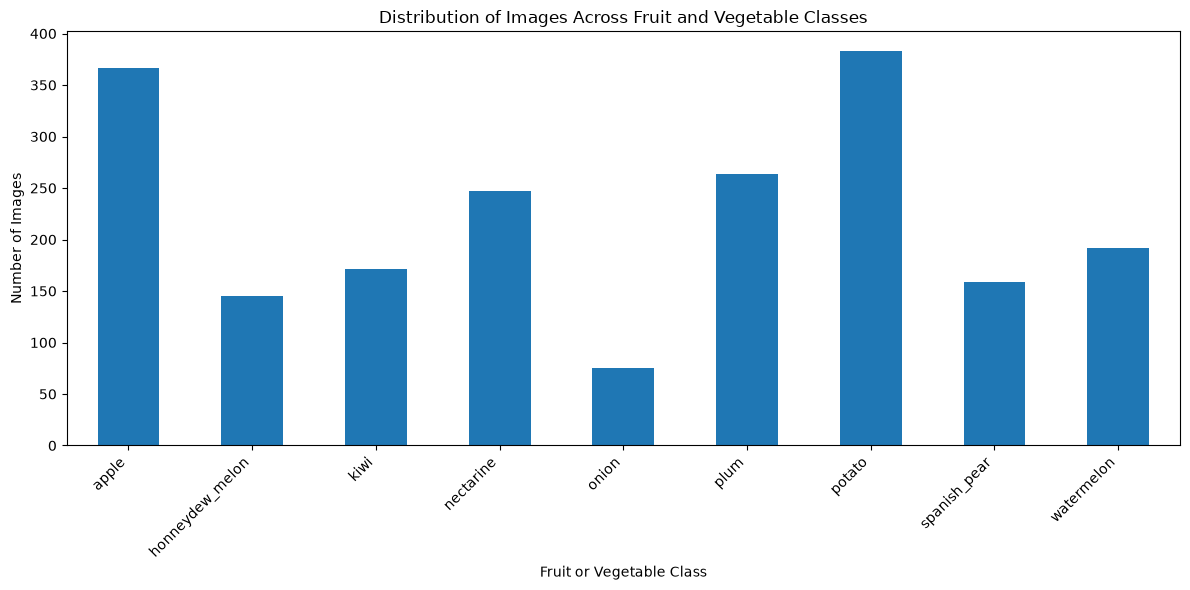

In [10]:
import matplotlib.pyplot as plt

# Create a bar chart showing the class distribution
plt.figure(figsize=(12, 6))

class_counts.plot(kind="bar")

plt.title("Distribution of Images Across Fruit and Vegetable Classes")
plt.xlabel("Fruit or Vegetable Class")
plt.ylabel("Number of Images")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.show()

### 2.2 Class Distribution Analysis

After filtering and combining selected categories, the dataset contains **2,003 images distributed across 9 classes**.

The class distribution is imbalanced. The largest class is *potato*, containing 383 images (19.1%), followed by *apple* with 367 images (18.3%). In contrast, the smallest class, *onion*, contains only 75 images (3.7%).

This imbalance may affect model performance, as classes with more training examples may be easier for the model to learn.

To address this issue, the following strategies will be considered:

- **Stratified data splitting:** Preserve approximately the same class proportions in the training, validation, and test datasets, while preventing images of the same object or photography session from appearing in multiple subsets.
- **Data augmentation:** Apply transformations such as rotations, flips, and brightness adjustments to training images to improve generalization.
- **Class weighting:** Investigate whether assigning higher importance to underrepresented classes improves classification performance.

Model performance will be evaluated using accuracy, macro-F1 score, and a confusion matrix.

Macro-F1 is particularly important because it gives equal weight to each class, regardless of the number of images.

**Conclusion:** The dataset contains sufficient examples to begin model development, but class imbalance must be considered during training and evaluation. Performance on underrepresented classes, particularly onion, should be examined carefully.

Find out the image-sizes

In [12]:
from PIL import Image
from collections import Counter

# Store image dimensions
image_dimensions = []

# Track images that cannot be opened
invalid_images = []

for item in dataset:
    image_path = item["image_path"]

    try:
        with Image.open(image_path) as img:
            image_dimensions.append(img.size)

    except Exception as e:
        invalid_images.append((image_path, str(e)))

# Count the most common image dimensions
dimension_counts = Counter(image_dimensions)

print("Most common image dimensions:\n")

for dimension, count in dimension_counts.most_common(10):
    print(f"{dimension}: {count} images")

print("\nUnique image dimensions:", len(dimension_counts))
print("Successfully opened images:", len(image_dimensions))
print("Images that could not be opened:", len(invalid_images))

Most common image dimensions:

(1024, 768): 2003 images

Unique image dimensions: 1
Successfully opened images: 2003
Images that could not be opened: 0


### 2.3 Image Dimensions and File Integrity

The dataset contains 2,003 images across 9 classes.

An examination of the image dimensions showed that all images have the same resolution of **1024 × 768 pixels**.

All 2,003 image files were successfully opened using the Pillow library, and no unreadable files were detected during this initial inspection.

**Key findings:**

- All images have consistent dimensions.
- No image files failed to open.
- The original images have an aspect ratio of 4:3.
- Image resizing will be required before training the classification models.

For the initial experiments, a target image size of 100 × 100 pixels is being considered. However, resizing methods that preserve the original aspect ratio should be evaluated to avoid unnecessary image distortion.

**Conclusion:** The dataset has consistent image dimensions and no detected file-opening errors. Further quality checks, including visual inspection and duplicate detection, are needed before preprocessing and model training.

### 2.4 Visual Inspection of the Dataset

To better understand the visual characteristics of the dataset, sample images from each of the nine target classes are examined.

The purpose of this analysis is to identify potential differences in object appearance, backgrounds, lighting conditions, and image quality.

Visual inspection may also reveal potential challenges for image classification, such as similarities between different classes or variations within the same class.

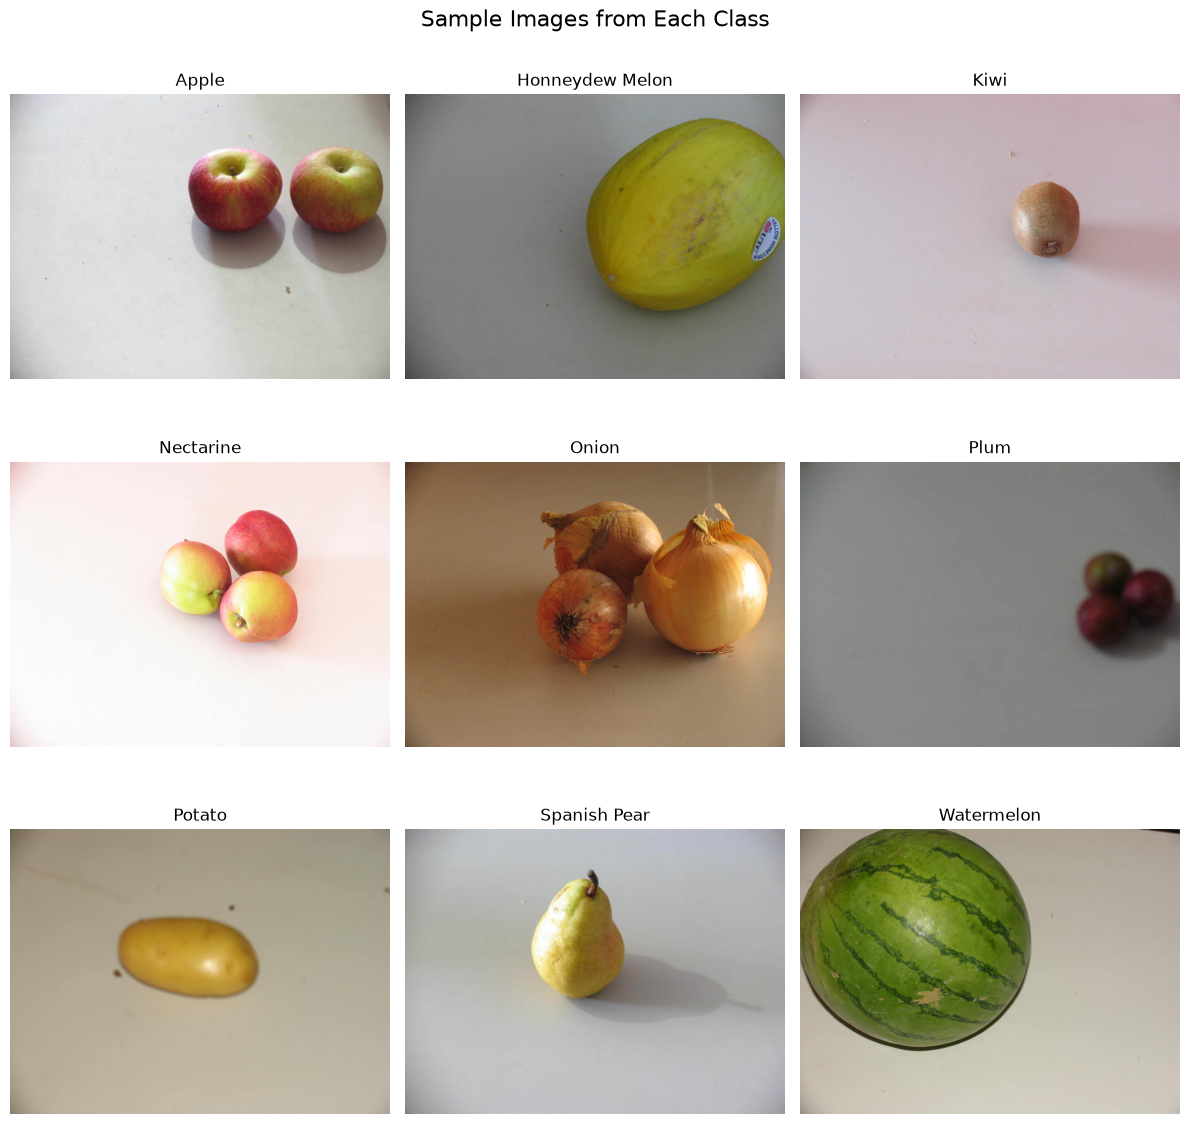

In [13]:
import matplotlib.pyplot as plt
from PIL import Image

# Get all target classes
classes = sorted(df["target_class"].unique())

# Create a figure with 3 rows and 3 columns
fig, axes = plt.subplots(3, 3, figsize=(12, 12))

# Display one example image from each class
for ax, class_name in zip(axes.flat, classes):

    # Select the first image from the class
    sample = df[df["target_class"] == class_name].iloc[0]

    # Open the image
    with Image.open(sample["image_path"]) as img:
        image = img.convert("RGB")

    # Display the image
    ax.imshow(image)
    ax.set_title(class_name.replace("_", " ").title())
    ax.axis("off")

plt.suptitle("Sample Images from Each Class", fontsize=16)
plt.tight_layout()
plt.show()

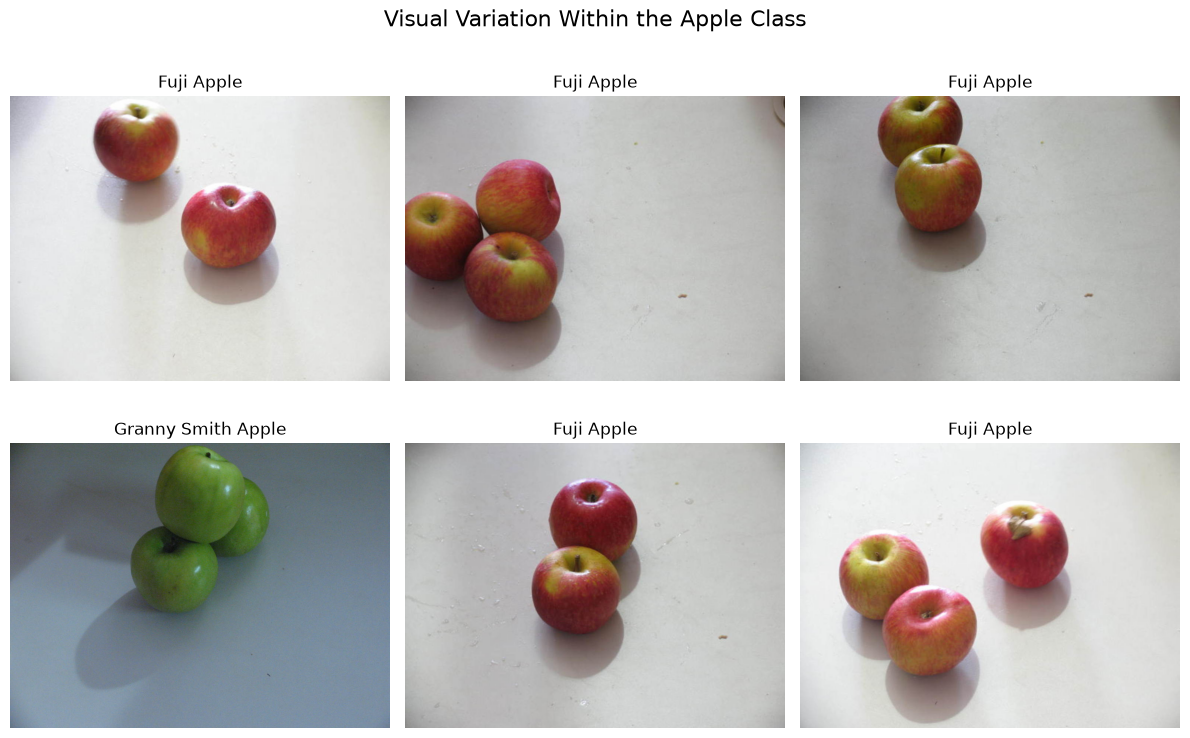

In [14]:
import matplotlib.pyplot as plt
from PIL import Image

# Select the class to examine
selected_class = "apple"

# Get all images belonging to the selected class
class_images = df[df["target_class"] == selected_class]

# Select 6 random images for visual inspection
sample_images = class_images.sample(
    n=min(6, len(class_images)),
    random_state=42
)

# Create a figure
fig, axes = plt.subplots(2, 3, figsize=(12, 8))

# Display the selected images
for ax, (_, row) in zip(axes.flat, sample_images.iterrows()):

    with Image.open(row["image_path"]) as img:
        image = img.convert("RGB")

    ax.imshow(image)
    ax.set_title(row["original_class"].replace("_", " ").title())
    ax.axis("off")

# Hide unused axes if fewer than 6 images are available
for ax in axes.flat[len(sample_images):]:
    ax.axis("off")

plt.suptitle(
    f"Visual Variation Within the {selected_class.title()} Class",
    fontsize=16
)

plt.tight_layout()
plt.show()

### 2.5 Visual Inspection Findings

A visual inspection of sample images from the nine target classes revealed several characteristics that may influence model performance.

**Backgrounds and lighting**

Most images have relatively simple, neutral backgrounds, making the objects visually distinguishable. However, lighting conditions vary between images, with some appearing darker or more strongly illuminated than others.

The relatively consistent backgrounds may also limit the model's ability to generalize to real-world photographs taken in different environments.

**Image quality and object size**

Some images appear slightly blurred or poorly illuminated. Additionally, the objects occupy different proportions of the image. For example, the kiwi occupies a relatively small area, while the watermelon fills a much larger portion of its image.

These differences should be considered when selecting image preprocessing and resizing techniques.

**Variation within classes**

The apple class contains both Fuji and Granny Smith apples. The sample images show noticeable differences in color and appearance between these varieties.

This variation requires the classification model to learn features that generalize across different appearances of the same target class.

**Potential data leakage**

Several images appear to have similar backgrounds, lighting conditions, and object arrangements, suggesting that some photographs may originate from the same photography session.

If closely related images are distributed across training, validation, and test sets, model performance may be overestimated.

Further investigation is therefore required before splitting the dataset.

**Conclusion**

The visual inspection revealed variations in image quality, lighting, object size, and appearance within classes.

These findings highlight the importance of appropriate preprocessing, careful dataset splitting, and evaluation using independent photographs.

### 2.6 Duplicate Detection and Data Leakage

Before splitting the dataset into training, validation, and test sets, it is important to investigate whether duplicate or closely related images exist.

Duplicate images may introduce data leakage if identical or highly similar images appear in multiple subsets.

This could lead to overly optimistic model evaluation results.

The first step is to identify exact duplicates using SHA-256 hashing.

Images with identical file contents will produce the same SHA-256 hash, allowing exact file duplicates to be detected without modifying the original dataset.

In [15]:
import hashlib
from collections import defaultdict

# Function to calculate SHA-256 hash
def calculate_hash(file_path):
    sha256 = hashlib.sha256()

    with open(file_path, "rb") as file:
        for chunk in iter(lambda: file.read(8192), b""):
            sha256.update(chunk)

    return sha256.hexdigest()


# Store image paths grouped by hash
hash_groups = defaultdict(list)

# Calculate hashes for all images
for image_path in df["image_path"]:
    image_hash = calculate_hash(image_path)
    hash_groups[image_hash].append(image_path)


# Identify duplicate groups
duplicate_groups = {
    image_hash: paths
    for image_hash, paths in hash_groups.items()
    if len(paths) > 1
}

# Count duplicate files beyond the first copy
duplicate_count = sum(
    len(paths) - 1
    for paths in duplicate_groups.values()
)

# Display results
print("Total images:", len(df))
print("Unique file hashes:", len(hash_groups))
print("Duplicate groups:", len(duplicate_groups))
print("Extra duplicate files:", duplicate_count)

# Display examples if duplicates exist
if duplicate_groups:
    print("\nExamples of duplicate images:\n")

    for image_hash, paths in list(duplicate_groups.items())[:5]:
        print("Duplicate group:")

        for path in paths:
            print(" -", path)

        print()

else:
    print("\nNo exact file duplicates detected.")

Total images: 2003
Unique file hashes: 2003
Duplicate groups: 0
Extra duplicate files: 0

No exact file duplicates detected.


### 2.7 Exact Duplicate Detection Results

SHA-256 hashing was used to identify exact file duplicates within the filtered dataset.

**Results:**
- Total images examined: 2,003
- Unique SHA-256 hashes: 2,003
- Duplicate groups: 0
- Extra duplicate files: 0

No exact file duplicates were detected.

However, this method only identifies files with identical binary content. It does not detect visually similar images, such as photographs of the same objects taken from slightly different angles.

Therefore, further investigation of near-duplicate and related images is necessary before splitting the dataset into training, validation, and test sets.

This is particularly important to reduce the risk of data leakage and ensure reliable model evaluation.

### 2.8 Near-Duplicate Detection Using Perceptual Hashing

Although no exact file duplicates were detected, visually similar images may still exist in the dataset.

Perceptual hashing (pHash) is used to investigate potential near-duplicates.

Unlike cryptographic hashing, perceptual hashing generates similar hash values for images with similar visual characteristics.

The similarity between two images is measured using the Hamming distance between their perceptual hashes.

A smaller Hamming distance indicates greater similarity.

This analysis aims to identify potentially related images that may introduce data leakage if distributed across training, validation, and test sets.

However, perceptual hashing alone cannot determine whether images originate from the same object or photography session. Potential matches must therefore be interpreted carefully.

In [16]:
import imagehash
from PIL import Image

# Store perceptual hashes
phashes = []

# Calculate pHash for each image
for image_path in df["image_path"]:

    with Image.open(image_path) as img:
        phash = imagehash.phash(img.convert("RGB"))

    phashes.append(phash)

# Add hashes to the DataFrame
df["phash"] = phashes

# Display results
print("Total images:", len(df))
print("Calculated perceptual hashes:", len(phashes))
print("Unique perceptual hashes:", df["phash"].nunique())

Total images: 2003
Calculated perceptual hashes: 2003
Unique perceptual hashes: 1998


Number of groups with identical pHash values: 4
Number of images involved: 9


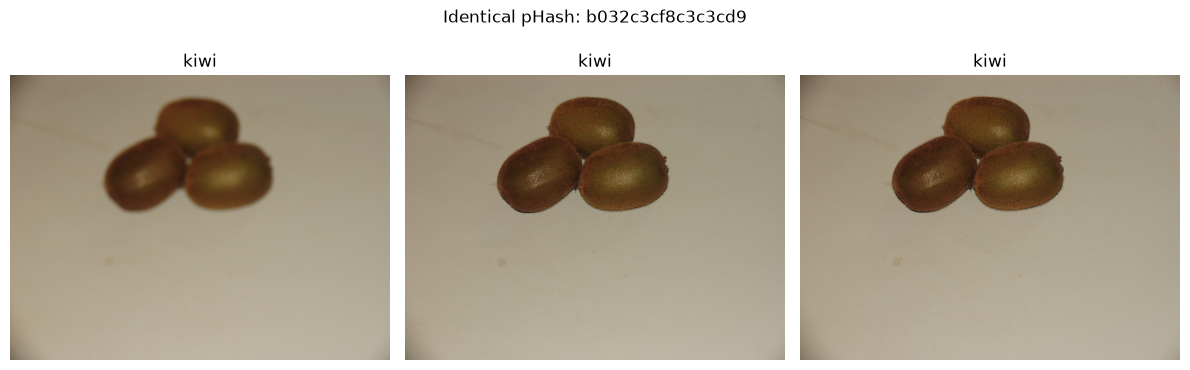

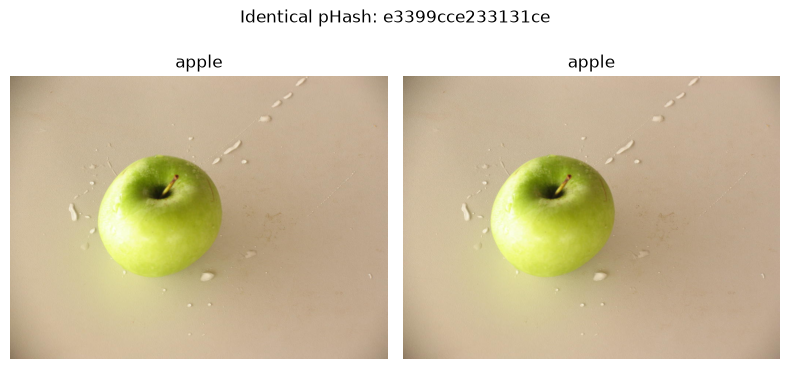

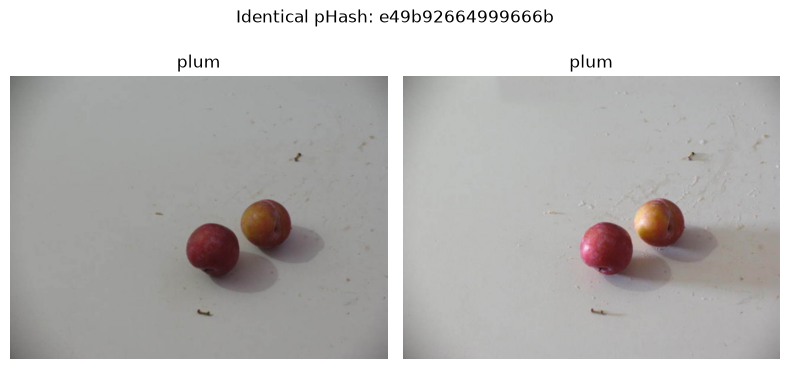

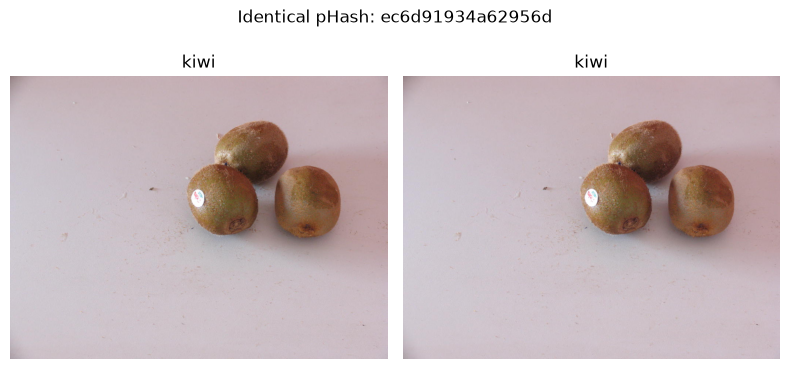

In [17]:
import matplotlib.pyplot as plt
from PIL import Image

# Convert perceptual hashes to strings for grouping
df["phash_string"] = df["phash"].astype(str)

# Find images with identical perceptual hashes
duplicate_phash = df[
    df.duplicated(subset="phash_string", keep=False)
].copy()

# Group images by perceptual hash
phash_groups = duplicate_phash.groupby("phash_string")

print("Number of groups with identical pHash values:", len(phash_groups))
print("Number of images involved:", len(duplicate_phash))

# Visualize each group
for phash_value, group in phash_groups:

    fig, axes = plt.subplots(
        1,
        len(group),
        figsize=(4 * len(group), 4),
        squeeze=False
    )

    for ax, (_, row) in zip(axes.flat, group.iterrows()):

        with Image.open(row["image_path"]) as img:
            image = img.convert("RGB")

        ax.imshow(image)
        ax.set_title(row["target_class"])
        ax.axis("off")

    plt.suptitle(f"Identical pHash: {phash_value}")
    plt.tight_layout()
    plt.show()

### 2.9 Near-Duplicate Detection Results

Perceptual hashing (pHash) was applied to all 2,003 images to identify potentially similar photographs.

The analysis produced 1,998 unique perceptual hash values.

Further investigation identified **four groups containing a total of nine images with identical pHash values**.

The identified groups consisted of:

- **Kiwi:** Two separate groups containing three and two images.
- **Apple:** One group containing two images.
- **Plum:** One group containing two images.

Visual inspection revealed that the images within these groups appear highly similar, often showing the same objects in nearly identical positions.

Some differences in lighting and sharpness were observed.

These findings suggest that several images may originate from the same photography sessions.

Although no exact file duplicates were detected using SHA-256, perceptual hashing successfully identified groups of visually similar images.

**Implications for data splitting**

The identified images should be considered as potentially related observations when creating the training, validation, and test datasets.

To reduce the risk of data leakage, images confirmed to belong to the same object or photography session should be assigned to the same dataset subset.

However, identical pHash values do not guarantee that images are identical or originate from the same photography session.

Further investigation of images with low perceptual hash distances is therefore required.

**Conclusion**

The analysis identified four groups of potentially related images involving nine photographs. Additional similarity analysis is necessary before creating the final 80/10/10 dataset split.

### 2.10 Perceptual Hash Distance Analysis

To further investigate potential near-duplicates, pairwise Hamming distances between perceptual hashes were calculated.

Unlike the previous analysis, which focused on identical pHash values, this analysis also considers images with similar but non-identical hashes.

Images belonging to the same target class are compared using a preliminary Hamming distance threshold of 5.

The purpose is to identify potentially related photographs that may originate from the same object or photography session.

A low Hamming distance does not necessarily indicate that two images depict the same object. Therefore, potential matches require visual inspection before conclusions can be drawn about data leakage.

In [18]:
from itertools import combinations
import pandas as pd

# Maximum Hamming distance
threshold = 5

# Store potentially similar image pairs
similar_pairs = []

# Compare images within each target class
for class_name, group in df.groupby("target_class"):

    # Generate all possible image pairs within the class
    for (idx1, row1), (idx2, row2) in combinations(
        group.iterrows(), 2
    ):

        # Calculate Hamming distance between pHashes
        distance = row1["phash"] - row2["phash"]

        # Keep pairs with low Hamming distance
        if distance <= threshold:

            similar_pairs.append({
                "class": class_name,
                "image_1": row1["image_path"],
                "image_2": row2["image_path"],
                "distance": distance
            })

# Convert results to DataFrame
similar_pairs_df = pd.DataFrame(
    similar_pairs,
    columns=["class", "image_1", "image_2", "distance"]
)

# Sort by similarity
similar_pairs_df = similar_pairs_df.sort_values(
    by="distance"
).reset_index(drop=True)

# Display results
print("Hamming distance threshold:", threshold)
print("Total similar image pairs:", len(similar_pairs_df))

print("\nSimilar pairs per class:")

if not similar_pairs_df.empty:
    print(similar_pairs_df["class"].value_counts().sort_index())
else:
    print("No similar image pairs found.")

Hamming distance threshold: 5
Total similar image pairs: 36

Similar pairs per class:
class
apple               7
honneydew_melon     5
kiwi               15
nectarine           4
plum                4
potato              1
Name: count, dtype: int64


Number of image pairs by Hamming distance:



,Number of Pairs
distance,
0,6
1,0
2,14
3,0
4,16
5,0


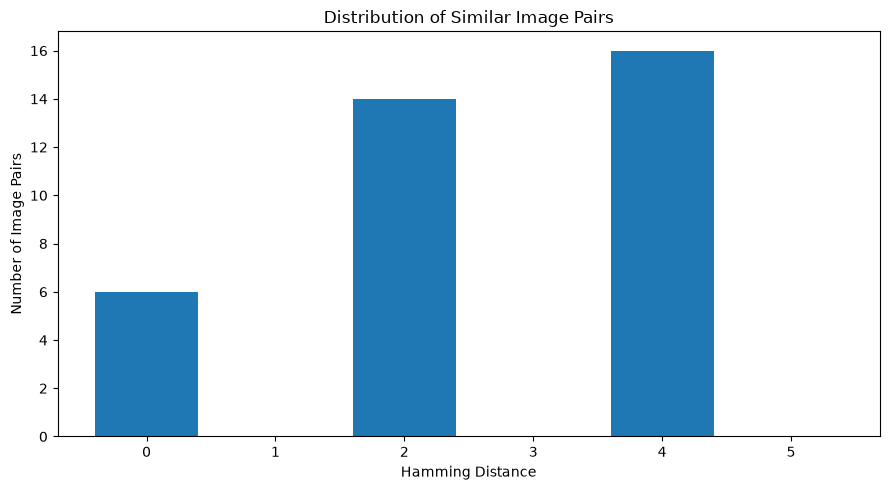

In [19]:
import matplotlib.pyplot as plt

# Count similar image pairs by Hamming distance
distance_counts = (
    similar_pairs_df["distance"]
    .value_counts()
    .reindex(range(threshold + 1), fill_value=0)
    .sort_index()
)

# Display table
print("Number of image pairs by Hamming distance:\n")
display(distance_counts.to_frame(name="Number of Pairs"))

# Create bar chart
plt.figure(figsize=(9, 5))

plt.bar(
    distance_counts.index,
    distance_counts.values
)

plt.title("Distribution of Similar Image Pairs")
plt.xlabel("Hamming Distance")
plt.ylabel("Number of Image Pairs")
plt.xticks(range(threshold + 1))

plt.tight_layout()
plt.show()

### 2.11 Summary of Potential Near-Duplicates

The perceptual hash distance analysis identified 36 image pairs with a Hamming distance of 5 or less.

The distribution of similar pairs was:

- Distance 0: 6 pairs
- Distance 2: 14 pairs
- Distance 4: 16 pairs

The largest number of potentially similar pairs was found in the kiwi class.

However, the number of image pairs does not directly represent the number of unique images involved, since individual images may appear in multiple pairs.

Further investigation is required to determine how many unique photographs are involved and whether the identified similarities indicate shared objects or photography sessions.

These findings will inform the creation of a leakage-aware training, validation, and test split.

In [20]:
# Collect all image paths involved in similar pairs
similar_images = set(similar_pairs_df["image_1"]).union(
    set(similar_pairs_df["image_2"])
)

# Count unique images
unique_similar_images = len(similar_images)

# Calculate percentage of the dataset
percentage_similar = (
    unique_similar_images / len(df)
) * 100

print("Total images in dataset:", len(df))

print("Total similar image pairs:", len(similar_pairs_df))

print("Unique images involved:", unique_similar_images)

print(f"Percentage of dataset involved: {percentage_similar:.2f}%")

Total images in dataset: 2003
Total similar image pairs: 36
Unique images involved: 58
Percentage of dataset involved: 2.90%


### 2.12 Visual Inspection of Potential Near-Duplicates

To investigate the results of the perceptual hash analysis, image pairs with a Hamming distance of 2 were selected for visual inspection.

The purpose is to determine whether the identified similarities represent:

- Different photographs of the same objects.
- Images captured during the same photography session.
- Different objects with similar visual characteristics.

This distinction is important because visually similar images do not necessarily represent data leakage.

The findings will help determine whether related images should be grouped together when creating the training, validation, and test datasets.

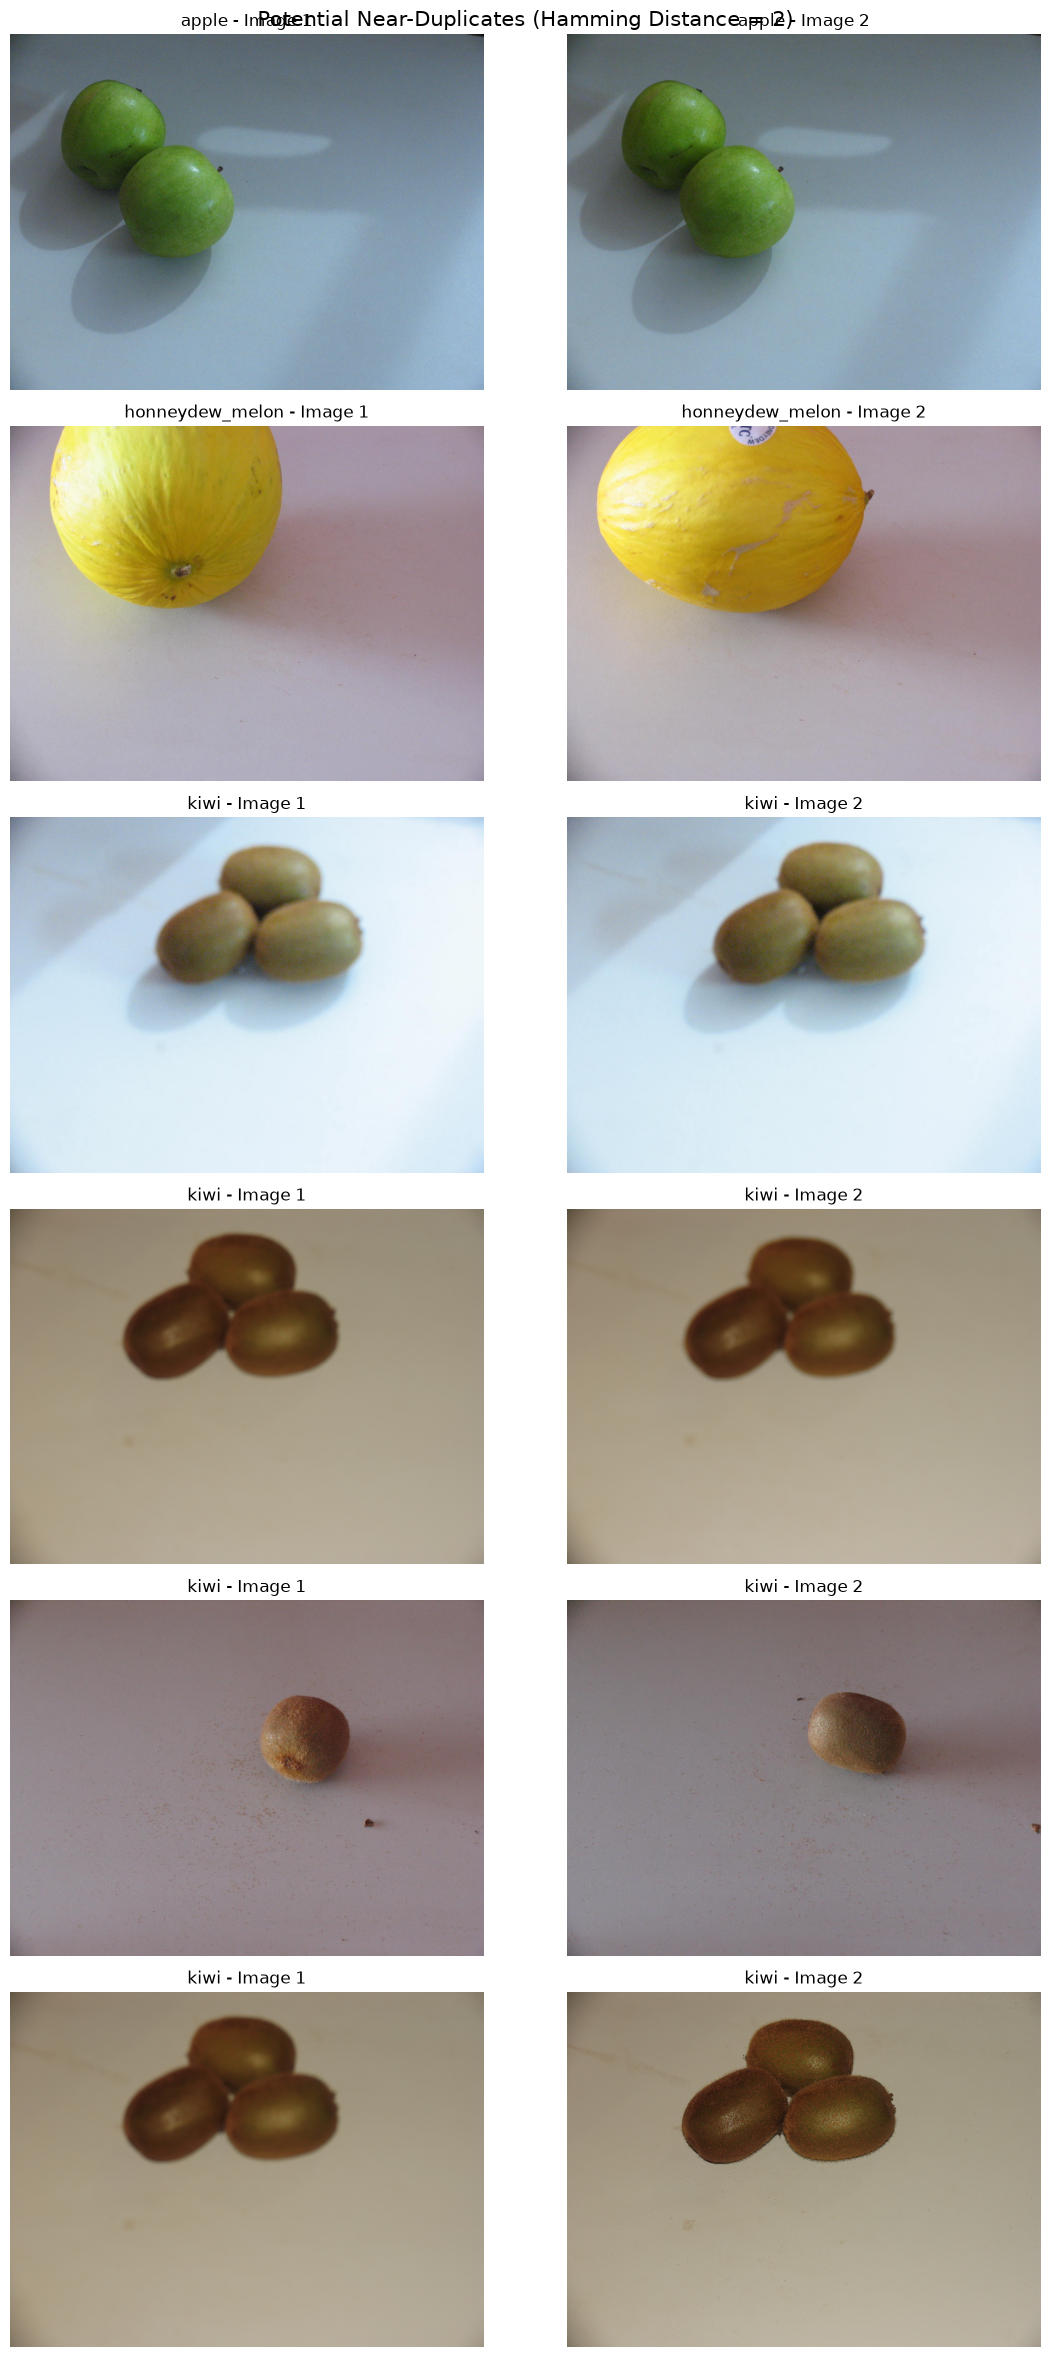

In [21]:
import matplotlib.pyplot as plt
from PIL import Image

# Select image pairs with Hamming distance = 2
pairs_to_inspect = similar_pairs_df[
    similar_pairs_df["distance"] == 2
]

# Display up to 6 image pairs
n_pairs = min(6, len(pairs_to_inspect))

fig, axes = plt.subplots(
    n_pairs, 2,
    figsize=(12, 4 * n_pairs),
    squeeze=False
)

for i, (_, row) in enumerate(
    pairs_to_inspect.head(n_pairs).iterrows()
):

    img1 = Image.open(row["image_1"])
    img2 = Image.open(row["image_2"])

    axes[i, 0].imshow(img1)
    axes[i, 1].imshow(img2)

    axes[i, 0].set_title(
        f"{row['class']} - Image 1"
    )

    axes[i, 1].set_title(
        f"{row['class']} - Image 2"
    )

    axes[i, 0].axis("off")
    axes[i, 1].axis("off")

plt.suptitle(
    "Potential Near-Duplicates (Hamming Distance = 2)",
    fontsize=15
)

plt.tight_layout()
plt.show()

### 2.12.1 Visual Inspection – Results and Implications

Visual inspection was performed on six image pairs with a perceptual hash (pHash) Hamming distance of 2.

The analysis revealed several examples of highly similar photographs across different fruit classes.

**Key observations:**

- **Apple:** The two images appear almost identical, showing the same two green apples in nearly identical positions.
- **Honeydew melon:** The images appear to show the same melon photographed from different angles.
- **Kiwi:** Several image pairs show nearly identical arrangements of kiwifruits, with minor differences in lighting, sharpness, or positioning.

These findings suggest that some images may originate from the same photography sessions or depict the same physical objects.

Although a low Hamming distance indicates perceptual similarity, it does not necessarily confirm that two photographs show the same objects.

#### Implications for Data Splitting

The visual inspection highlights a potential risk of data leakage when randomly dividing the dataset into training, validation, and test sets.

If photographs of the same physical objects appear in multiple subsets, model evaluation may produce overly optimistic performance estimates.

To reduce this risk, a **group-aware and stratified data splitting strategy** will be considered, provided that reliable groups of related photographs can be identified.

The intended dataset proportions remain:

- **Training:** 80%
- **Validation:** 10%
- **Test:** 10%

Images confirmed to originate from the same object or photography session should be assigned to the same subset.

Further investigation of image filenames and potential photography sequences will be conducted before finalizing the dataset split.

**Conclusion:** The visual inspection supports the need to consider relationships between photographs when preparing the dataset. Additional analysis is required to establish reliable grouping criteria and minimize potential data leakage.

### 2.13 Investigation of Image File Naming

Visual inspection of image pairs with a Hamming distance of 2 revealed several potentially related photographs.

Some images appear to show the same objects in nearly identical positions, while others may represent different views of the same object.

These observations suggest that certain photographs may not be independent observations.

To further investigate potential relationships between images, the dataset's file naming conventions will be examined.

The objective is to determine whether filenames contain information about image sequences or photography sessions that could support a group-aware dataset split.

In [22]:
from pathlib import Path

# Display example filenames from each original image folder
print("Example filenames from each image folder:\n")

for folder in sorted(raw_images_path.iterdir()):

    if folder.is_dir():

        image_files = sorted([
            file.name
            for file in folder.iterdir()
            if file.suffix.lower() in [".jpg", ".jpeg", ".png"]
        ])

        print(f"\n{folder.name}")
        print("-" * 40)

        for filename in image_files[:10]:
            print(filename)

        print(f"Total images: {len(image_files)}")

Example filenames from each image folder:


agata_potato
----------------------------------------
agata_potato_001.jpg
agata_potato_002.jpg
agata_potato_003.jpg
agata_potato_004.jpg
agata_potato_005.jpg
agata_potato_006.jpg
agata_potato_007.jpg
agata_potato_008.jpg
agata_potato_009.jpg
agata_potato_010.jpg
Total images: 201

asterix_potato
----------------------------------------
asterix_potato_001.jpg
asterix_potato_002.jpg
asterix_potato_003.jpg
asterix_potato_004.jpg
asterix_potato_005.jpg
asterix_potato_006.jpg
asterix_potato_007.jpg
asterix_potato_008.jpg
asterix_potato_009.jpg
asterix_potato_010.jpg
Total images: 182

cashew
----------------------------------------
cashew_001.jpg
cashew_002.jpg
cashew_003.jpg
cashew_004.jpg
cashew_005.jpg
cashew_006.jpg
cashew_007.jpg
cashew_008.jpg
cashew_009.jpg
cashew_010.jpg
Total images: 210

diamond_peach
----------------------------------------
diamond_peach_001.jpg
diamond_peach_002.jpg
diamond_peach_003.jpg
diamond_peach_004.jpg
diamond_

### 2.14 Filename Patterns Among Similar Images

The dataset contains sequentially numbered image files organized into folders representing different fruit and vegetable varieties.

However, the numbering system does not necessarily reflect the order in which photographs were taken.

To investigate whether filenames provide information about potentially related photographs, the filenames of image pairs with a perceptual hash Hamming distance of 5 or less will be examined.

The objective is to determine whether visually similar images tend to have nearby file numbers.

If such a pattern exists, filename sequences may provide additional information for identifying groups of related photographs.

However, filename proximity alone will not be considered sufficient evidence that images originate from the same object or photography session.

In [23]:
from pathlib import Path
import re
import pandas as pd

# Extract the numerical suffix from an image filename
def extract_image_number(path):
    filename = Path(path).stem

    match = re.search(r"_(\d+)$", filename)

    if match:
        return int(match.group(1))

    return None


# Create a copy of the similar image pairs
filename_analysis = similar_pairs_df.copy()

# Extract filenames
filename_analysis["filename_1"] = filename_analysis["image_1"].apply(
    lambda x: Path(x).name
)

filename_analysis["filename_2"] = filename_analysis["image_2"].apply(
    lambda x: Path(x).name
)

# Extract image numbers
filename_analysis["number_1"] = filename_analysis["image_1"].apply(
    extract_image_number
)

filename_analysis["number_2"] = filename_analysis["image_2"].apply(
    extract_image_number
)

# Check whether images belong to the same original folder
filename_analysis["same_folder"] = filename_analysis.apply(
    lambda row: Path(row["image_1"]).parent
    == Path(row["image_2"]).parent,
    axis=1
)

# Calculate numerical distance only for images in the same folder
filename_analysis["number_difference"] = (
    filename_analysis["number_1"]
    - filename_analysis["number_2"]
).abs()

filename_analysis.loc[
    ~filename_analysis["same_folder"],
    "number_difference"
] = pd.NA

# Display results
display(
    filename_analysis[
        [
            "class",
            "filename_1",
            "filename_2",
            "distance",
            "same_folder",
            "number_difference"
        ]
    ].sort_values(
        by=["distance", "number_difference"]
    )
)

,class,filename_1,filename_2,distance,same_folder,number_difference
0,apple,granny_smith_apple_132.jpg,granny_smith_apple_133.jpg,0,True,1.0
1,kiwi,kiwi_017.jpg,kiwi_018.jpg,0,True,1.0
2,kiwi,kiwi_153.jpg,kiwi_154.jpg,0,True,1.0
4,kiwi,kiwi_152.jpg,kiwi_153.jpg,0,True,1.0
5,plum,plum_135.jpg,plum_136.jpg,0,True,1.0
3,kiwi,kiwi_152.jpg,kiwi_154.jpg,0,True,2.0
7,honneydew_melon,honneydew_melon_083.jpg,honneydew_melon_084.jpg,2,True,1.0
8,kiwi,kiwi_149.jpg,kiwi_150.jpg,2,True,1.0
9,kiwi,kiwi_151.jpg,kiwi_152.jpg,2,True,1.0
15,apple,granny_smith_apple_002.jpg,granny_smith_apple_003.jpg,2,True,1.0


### 2.14.1 Filename Analysis – Results and Interpretation

The filename analysis was conducted to investigate whether visually similar images tend to have nearby sequential file numbers.

A total of 36 image pairs with a perceptual hash Hamming distance of 5 or less were examined.

**Key findings:**

- All 36 identified image pairs originated from the same source folder.
- Many visually similar image pairs had consecutive or closely numbered filenames.
- Several image pairs had larger numerical differences, ranging up to 45.
- Examples of consecutive filenames included `kiwi_017.jpg` and `kiwi_018.jpg`, as well as `plum_135.jpg` and `plum_136.jpg`.
- Other potentially similar pairs, such as `honeydew_melon_086.jpg` and `honeydew_melon_131.jpg`, had substantially different file numbers.

#### Interpretation

The results suggest that sequential filenames may contain useful information about the organization of the image dataset.

The frequent occurrence of similar images with nearby file numbers is consistent with the possibility that some photographs were captured in sequences.

However, the presence of visually similar images with larger numerical differences indicates that filename proximity alone cannot reliably identify related photographs.

Furthermore, similar perceptual hashes do not necessarily indicate that images depict the same physical objects.

#### Implications for Data Splitting

These findings highlight the importance of considering potential relationships between photographs before dividing the dataset into training, validation, and test sets.

A group-aware splitting strategy may help reduce data leakage if reliable groups of related images can be established.

The intended dataset proportions remain:

- Training: 80%
- Validation: 10%
- Test: 10%

Further investigation is required before defining the final grouping strategy.

**Conclusion:** Filename patterns provide potentially useful supplementary information, but should not be used as the sole criterion for grouping related images.

### 2.15 Sequential Image Similarity Analysis

The previous analysis revealed that many visually similar images have consecutive or closely numbered filenames.

To investigate whether this pattern extends across the dataset, the perceptual similarity between sequentially numbered images will be examined.

The analysis focuses on pairs of images that:

- Belong to the same original source folder.
- Have consecutive numerical filename suffixes.
- Have valid perceptual hash values.

The Hamming distance between each consecutive image pair will be calculated.

The objective is to investigate whether sequential filenames are associated with perceptual similarity, which may provide additional evidence about the dataset's organization.

However, perceptual similarity alone cannot establish whether images depict the same physical objects or originate from the same photography session.

In [24]:
import pandas as pd
from pathlib import Path
import re

# Create a copy of the dataset
sequential_df = df.copy()

# Extract original source folder
sequential_df["source_folder"] = sequential_df["image_path"].apply(
    lambda x: Path(x).parent.name
)

# Extract image number from filename
def get_image_number(path):
    match = re.search(r"_(\d+)$", Path(path).stem)
    return int(match.group(1)) if match else None

sequential_df["image_number"] = sequential_df["image_path"].apply(
    get_image_number
)

# Store consecutive image pairs
sequential_pairs = []

# Group images by original source folder
for folder_name, group in sequential_df.groupby("source_folder"):

    group = group.dropna(
        subset=["image_number", "phash"]
    ).sort_values("image_number")

    records = group.to_dict("records")

    for i in range(len(records) - 1):

        img1 = records[i]
        img2 = records[i + 1]

        # Only compare consecutive file numbers
        if img2["image_number"] - img1["image_number"] == 1:

            distance = img1["phash"] - img2["phash"]

            sequential_pairs.append({
                "source_folder": folder_name,
                "image_1": Path(img1["image_path"]).name,
                "image_2": Path(img2["image_path"]).name,
                "distance": distance
            })

# Convert results into a DataFrame
sequential_pairs_df = pd.DataFrame(
    sequential_pairs,
    columns=[
        "source_folder",
        "image_1",
        "image_2",
        "distance"
    ]
)

print("Total consecutive image pairs:", len(sequential_pairs_df))

print("\nHamming distance statistics:")
print(sequential_pairs_df["distance"].describe())

print("\nConsecutive pairs with Hamming distance <= 5:")
print((sequential_pairs_df["distance"] <= 5).sum())

Total consecutive image pairs: 1992

Hamming distance statistics:
count    1992.000000
mean       25.332329
std         6.849608
min         0.000000
25%        22.000000
50%        26.000000
75%        30.000000
max        42.000000
Name: distance, dtype: float64

Consecutive pairs with Hamming distance <= 5:
18


### 2.16 Interpretation of Sequential Image Similarity

The sequential image similarity analysis examined 1,992 pairs of images with consecutive filename numbers within the same original source folder.

The average perceptual Hamming distance was 25.33, with a median of 26 and a standard deviation of 6.85.

Only 18 image pairs (0.90%) had a Hamming distance of 5 or less, indicating that very high perceptual similarity was relatively uncommon among consecutively numbered images.

These findings suggest that consecutive filenames do not necessarily correspond to nearly identical images.

However, perceptual hashing has limitations. Images of the same physical object photographed from different angles, distances, or lighting conditions may have substantially different perceptual hashes.

Therefore, the results do not rule out the possibility that consecutive images belong to the same photography session.

**Implications for data splitting:**

The findings highlight the importance of considering potential dependencies between images before dividing the dataset into training, validation, and test sets.

A purely random stratified split could introduce data leakage if photographs of the same physical objects appear in different subsets.

Further investigation is needed to determine whether reliable photography groups can be identified.

The intended data split remains:

- Training: 80%
- Validation: 10%
- Test: 10%

Where possible, related images should be assigned to the same subset to reduce the risk of data leakage.

### 2.18 Background Color Analysis

During the visual inspection of the dataset, several images appeared
to have similar backgrounds and lighting conditions.

This raises the possibility that the classification models could
learn background-related patterns rather than focusing exclusively
on the visual characteristics of fruits and vegetables.

To investigate this, we estimate the background color of each image
by extracting small regions from its four corners.

The average RGB values of these regions are used as an approximation
of the background color.

We then compare these values across the nine target classes to
identify potential systematic differences.

This analysis is exploratory, as image corners may contain shadows,
objects, or other visual elements that do not represent the background.

In [26]:
import numpy as np
import pandas as pd
from PIL import Image

# Function to estimate background color from image corners
def estimate_background_color(image_path, corner_size=50):

    with Image.open(image_path) as img:
        img = img.convert("RGB")
        image = np.array(img)

    height, width, _ = image.shape

    # Extract four corner regions
    corners = [
        image[:corner_size, :corner_size],
        image[:corner_size, width-corner_size:],
        image[height-corner_size:, :corner_size],
        image[height-corner_size:, width-corner_size:]
    ]

    # Combine all corner pixels
    corner_pixels = np.concatenate(
        [corner.reshape(-1, 3) for corner in corners],
        axis=0
    )

    # Calculate average RGB values
    mean_rgb = corner_pixels.mean(axis=0)

    return mean_rgb


# Calculate background colors for all images
background_results = []

for _, row in df.iterrows():

    image_path = row["image_path"]

    mean_rgb = estimate_background_color(image_path)

    background_results.append({
        "target_class": row["target_class"],
        "red": mean_rgb[0],
        "green": mean_rgb[1],
        "blue": mean_rgb[2]
    })


# Convert results into a DataFrame
background_df = pd.DataFrame(background_results)

# Calculate average RGB values per class
background_summary = (
    background_df
    .groupby("target_class")[["red", "green", "blue"]]
    .mean()
    .round(2)
)

print("Average estimated background RGB values per class:\n")

display(background_summary)

Average estimated background RGB values per class:



,red,green,blue
target_class,,,
apple,150.94,151.69,149.73
honneydew_melon,139.53,133.76,141.15
kiwi,147.34,143.31,146.96
nectarine,180.82,162.91,171.20
onion,146.56,116.56,88.43
plum,122.17,123.27,121.85
potato,119.90,99.66,77.18
spanish_pear,108.20,110.19,108.70
watermelon,150.61,134.20,111.47


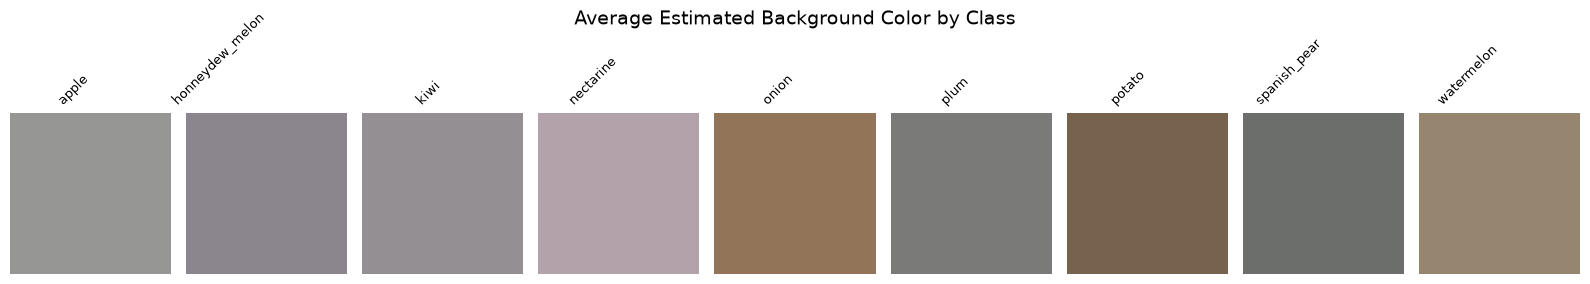

In [27]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(
    1,
    len(background_summary),
    figsize=(16, 3)
)

for ax, (class_name, row) in zip(
    axes,
    background_summary.iterrows()
):
    rgb = row[["red", "green", "blue"]].to_numpy(dtype=float) / 255

    color_patch = np.ones((100, 100, 3)) * rgb

    ax.imshow(color_patch)
    ax.set_title(class_name, rotation=45, ha="right", fontsize=9)
    ax.axis("off")

plt.suptitle(
    "Average Estimated Background Color by Class",
    fontsize=14
)

plt.tight_layout()
plt.show()

### 2.19 Background Color Variation Within Classes

The previous analysis revealed differences in the average estimated corner colors between target classes.

However, class averages alone do not indicate how consistent these colors are within each class.

To investigate this, we calculate the standard deviation of the estimated RGB values for each target class.

A low standard deviation indicates relatively consistent corner colors within a class, while a high standard deviation indicates greater variation.

This analysis helps us assess whether the observed differences between class averages represent consistent patterns or substantial variation across individual images.

The results remain exploratory because corner colors are only an approximation of the actual background.

In [28]:
# Calculate standard deviation of estimated corner RGB values
background_std = (
    background_df
    .groupby("target_class")[["red", "green", "blue"]]
    .std()
    .round(2)
)

print("Standard deviation of estimated corner RGB values per class:\n")

display(background_std)

Standard deviation of estimated corner RGB values per class:



,red,green,blue
target_class,,,
apple,39.28,33.29,30.65
honneydew_melon,30.35,25.44,31.96
kiwi,47.14,38.25,38.71
nectarine,28.57,26.42,24.19
onion,17.67,14.18,11.35
plum,23.77,24.31,23.86
potato,31.79,30.86,29.28
spanish_pear,37.27,37.31,39.15
watermelon,18.01,19.18,22.69


### 2.20 Background Color Analysis – Findings and Implications

The background color analysis revealed differences in the estimated corner colors across the nine target classes.

The average RGB values indicated that some classes had relatively neutral gray corner colors, while others showed warmer or lighter color tones. For example, apple and plum had approximately neutral gray averages, whereas onion and potato had warmer, brownish averages.

The standard deviations also differed between classes. Kiwi and spanish_pear showed relatively high variation in their estimated corner colors, while onion and watermelon showed more consistent values.

These findings suggest that the dataset contains class-associated differences in image corner colors. Such patterns could potentially provide unintended cues to an image classification model.

However, the analysis has several limitations:

- Image corners do not necessarily represent the background, as they may contain parts of the objects, shadows, or reflections.
- Differences in average RGB values do not establish whether the color distributions are sufficiently distinct to predict the target classes.
- The analysis does not demonstrate that a trained model actually relies on background information.

**Implications for model development**

The findings highlight a potential risk of shortcut learning, where a model uses visual cues that are correlated with the target classes but may not generalize to new environments.

To address this risk, model development should include appropriate training-data augmentation and evaluation on external photographs taken under different conditions.

In addition, potentially related images should be kept within the same dataset partition where reliable relationships can be identified, reducing the risk of data leakage.

Overall, the analysis provides useful evidence of potential dataset biases and motivates careful evaluation of model generalization beyond the original image collection.